# Analysis of LLM vulnerability detection on Juliet C/C++ 

Course:  T-742-CSDA (Computer security Defence against dark art)

Student Name: Poonam Vikram Kadam 

In this notebook we will perform the Analysis of LLM vulnerability detection on Juliet C/C++. For analysis we use 3 local model 
1. codellama:7b 
2. deepseek-coder:6.7b
3. qwen2.5-coder:7b 

In [45]:
import os, csv, math, random
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

SAMPLE = os.environ.get("JULIET_SAMPLE", "/Volumes/Seagate/juliet_data/llm_sample")
EV = os.path.join(SAMPLE, "evaluation")
OUT = os.path.join(EV, "report")
os.makedirs(OUT, exist_ok=True)

CWE_NAMES = {"CWE78": "OS Command Injection", "CWE121": "Stack Buffer Overflow",
             "CWE122": "Heap Buffer Overflow", "CWE190": "Integer Overflow",
             "CWE416": "Use After Free", "CWE476": "NULL Pointer Dereference"}

# Colours: fixed . 
MODEL_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5",
                                                    "#256abf", "#184f95", "#0d366b"])
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.titlesize": 11,
                     "axes.titleweight": "bold", "axes.titlecolor": INK, "figure.dpi": 110,
                     "savefig.dpi": 200, "savefig.bbox": "tight"})
pd.set_option("display.max_rows", 200)

##  Score the answers
 we run evaluate.py. It takes the answers of each model from the results folder and compares them with the correct answers in labels.csv.

For every file we check if the model said vulnerable or safe correctly (TP, FN, FP, TN). If the model found the bug, we also check if it gave the right CWE and the right line (we also accept it if the line is max 2 lines away).

Some answers could not be read because the model output was cut off. These are counted as "not vulnerable".
The results are saved in the evaluation folder and loaded below, so we can use them in the next sections.

In [46]:
import subprocess, sys
r = subprocess.run([sys.executable, "evaluate.py", "--sample", SAMPLE], capture_output=True, text=True)
print(r.stdout[-3000:], r.stderr[-2000:])


OVERALL
Model                Files  Accuracy  Recall  False alarms     F1  CWE exact  CWE related  Line exact  Line +-2  Sec/file
-------------------  -----  --------  ------  ------------  -----  ---------  -----------  ----------  --------  --------
codellama:7b           290     52.8%  100.0%         94.5%  67.9%      26.2%        52.4%       72.4%     86.9%      10.0
deepseek-coder:6.7b    290     70.0%   52.4%         12.4%  63.6%       9.2%        34.2%       68.4%     84.2%       6.8
qwen2.5-coder:7b       290     57.9%   89.7%         73.8%  68.1%      49.2%        73.8%       77.7%     94.6%       6.7

PER CWE (recall = vulnerable files found, false alarms = safe files flagged)
Model                CWE     Recall  False alarms     F1  CWE related  Line +-2
-------------------  ------  ------  ------------  -----  -----------  --------
codellama:7b         CWE78   100.0%        100.0%  66.7%         0.0%     56.0%
codellama:7b         CWE121  100.0%         96.0%  67.6%       

Results: 

- Files: How many files the model answered from given input (Total 290 = 145 vulnerable + 145 safe)
- Accuracy: shows how many files the model got right in total
- Recall: how many of the vulnerable files the model found
- False alarms: for how many safe files the model  called vulnerable 
- F1: model detection performance
- CWE exact / CWE related: for the bugs the model found, did it give the same CWE identification, or from the same family
- Line exact / Line +-2: for the bugs the model found, did it point to the flaw line, or max 2 lines away as error can be in +-2 lines. 
- Sec/file: average time used per file in seconds. 

Analysis :

Out of all 3 models DeepSeek has the great accuracy (70%) and  few false alarms (12.4%), but it only finds about half of the vulnerable files (52.4%).

CodeLlama finds all vulnerable files (100% recall), but it also says "vulnerable" for almost every safe file (94.5% false alarms). So the 100% recall does not mean it is good, it just flags everything. Qwen is similar but a bit better than CodeLlama findings (89.7% recall, 73.8% false alarms).

F1 score looks almost the same for all three models, and even a bit lower for DeepSeek. As F1 ignores the safe files, so it does not show the false alarm problem.

When a model finds a bug, it usually points to the right place arond 84-95% within 2 lines. DeepSeek faces difficulty to identify correct CWE's , it founds only 9.2% exact.

In [47]:
labels = pd.read_csv(os.path.join(SAMPLE, "labels.csv"), dtype={"variant": str})
det = pd.read_csv(os.path.join(EV, "details.csv"), dtype={"variant": str, "true_lines": str, "model_lines": str})
for col in ["said_vuln", "correct", "cwe_exact", "cwe_related", "line_exact", "line_near", "unparsed"]:
    det[col] = det[col].astype(str).str.lower().eq("true")
lang_of = lambda f: "C++" if f.endswith(".cpp") else "C"
labels["language"] = labels["file"].map(lang_of)
det["language"] = det["file"].map(lang_of)
cwe_order = sorted(labels["cwe"].unique(), key=lambda c: int(c[3:]))
models = sorted(det["model"].unique())
short = {m: m.replace(":", " ") for m in models}
print(f"{len(labels)} files, {len(cwe_order)} CWEs, models: {', '.join(models)}")

290 files, 6 CWEs, models: codellama:7b, deepseek-coder:6.7b, qwen2.5-coder:7b


In [48]:
def rates(df):
    """Confusion counts and rates for a set of answers."""
    tp = int(((df.label == "bad") & df.said_vuln).sum()); fn = int(((df.label == "bad") & ~df.said_vuln).sum())
    fp = int(((df.label == "good") & df.said_vuln).sum()); tn = int(((df.label == "good") & ~df.said_vuln).sum())
    p = lambda a, b: round(100 * a / b, 1) if b else None
    prec = tp / (tp + fp) if tp + fp else 0; rec = tp / (tp + fn) if tp + fn else 0
    d = math.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return {"Files": len(df), "TP": tp, "FN": fn, "FP": fp, "TN": tn,
            "Accuracy %": p(tp + tn, len(df)), "Recall %": p(tp, tp + fn), "Specificity %": p(tn, tn + fp),
            "Precision %": p(tp, tp + fp), "False alarm %": p(fp, fp + tn),
            "F1 %": round(200 * prec * rec / (prec + rec), 1) if prec + rec else 0.0,
            "MCC": round((tp * tn - fp * fn) / d, 3) if d else 0.0}

def found_rates(df):
    """Of the vulnerable files the model found: right CWE and right line."""
    f = df[(df.label == "bad") & df.said_vuln]
    p = lambda s: round(100 * s.mean(), 1) if len(f) else None
    return {"Bugs found": len(f), "CWE exact %": p(f.cwe_exact), "CWE related %": p(f.cwe_related),
            "Line exact %": p(f.line_exact), "Line ±2 %": p(f.line_near)}

def bootstrap_ci(df, reps=2000, seed=42):
    """95% confidence interval for accuracy, resampling files."""
    rng = random.Random(seed); c = list(df.correct); n = len(c)
    accs = sorted(sum(rng.choice(c) for _ in range(n)) / n for _ in range(reps))
    return f"{100 * accs[int(.025 * reps)]:.1f}–{100 * accs[int(.975 * reps) - 1]:.1f}"

def mcnemar(a, b):
    """Exact McNemar test on the files both models answered."""
    m = a[["file", "correct"]].merge(b[["file", "correct"]], on="file")
    only_a = int((m.correct_x & ~m.correct_y).sum()); only_b = int((~m.correct_x & m.correct_y).sum())
    n = only_a + only_b
    p = min(1.0, 2 * sum(math.comb(n, k) for k in range(min(only_a, only_b) + 1)) / 2 ** n) if n else 1.0
    return only_a, only_b, p

def save(df, name):
    df.to_csv(os.path.join(OUT, name), index=False)
    return df

def heatmap(matrix, rows, cols, title, label, name, vmax=100, cell="{:.0f}%", ns=None):
    fig, ax = plt.subplots(figsize=(2.2 + 1.45 * len(cols), 1.0 + 0.55 * len(rows)))
    im = ax.imshow([[float("nan") if v is None else v for v in r] for r in matrix],
                   cmap=BLUES, vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(cols)), cols, fontsize=9); ax.set_yticks(range(len(rows)), rows)
    ax.set_xticks([x - .5 for x in range(1, len(cols))], minor=True)
    ax.set_yticks([y - .5 for y in range(1, len(rows))], minor=True)
    ax.grid(which="minor", color="white", linewidth=2); ax.tick_params(which="both", length=0)
    for s in ax.spines.values(): s.set_visible(False)
    for i, r in enumerate(matrix):
        for j, v in enumerate(r):
            txt = "–" if v is None else cell.format(v) + (f"\nn={ns[i][j]}" if ns else "")
            ax.text(j, i, txt, ha="center", va="center", fontsize=9,
                    color="white" if v is not None and v > .55 * vmax else INK)
    cb = fig.colorbar(im, ax=ax, fraction=.04, pad=.03); cb.outline.set_visible(False); cb.set_label(label, color=INK2)
    ax.set_title(title, loc="left", pad=10)
    fig.savefig(os.path.join(OUT, name)); plt.show()

## 1. Dataset: what the models were tested on

In [49]:
rows = []
for c in cwe_order + ["Total"]:
    s = labels if c == "Total" else labels[labels.cwe == c]
    n = len(s)
    rows.append({"CWE": c, "Name": CWE_NAMES.get(c, ""), "Files": n,
                 "Bad": int((s.label == "bad").sum()), "Good": int((s.label == "good").sum()),
                 "C": int((s.language == "C").sum()), "C++": int((s.language == "C++").sum()),
                 "Variant 01": int((s.variant == "01").sum()), "Variant 09": int((s.variant == "09").sum()),
                 "% of dataset": round(100 * n / len(labels), 1)})
dataset = save(pd.DataFrame(rows), "1a_dataset_counts.csv")
dataset

,CWE,Name,Files,Bad,Good,C,C++,Variant 01,Variant 09,% of dataset
0,CWE78,OS Command Injection,50,25,25,50,0,22,28,17.2
1,CWE121,Stack Buffer Overflow,50,25,25,50,0,24,26,17.2
2,CWE122,Heap Buffer Overflow,50,25,25,26,24,30,20,17.2
3,CWE190,Integer Overflow,50,25,25,50,0,22,28,17.2
4,CWE416,Use After Free,50,25,25,12,38,32,18,17.2
5,CWE476,NULL Pointer Dereference,40,20,20,36,4,20,20,13.8
6,Total,,290,145,145,224,66,150,140,100.0


In [50]:
pct_cols = ["Bad", "Good", "C", "C++", "Variant 01", "Variant 09"]
dataset_pct = dataset[["CWE", "Name", "Files"]].copy()
for col in pct_cols:
    dataset_pct[col + " %"] = (100 * dataset[col] / dataset["Files"]).round(1)
save(dataset_pct, "1b_dataset_percent.csv")
dataset_pct

,CWE,Name,Files,Bad %,Good %,C %,C++ %,Variant 01 %,Variant 09 %
0,CWE78,OS Command Injection,50,50.0,50.0,100.0,0.0,44.0,56.0
1,CWE121,Stack Buffer Overflow,50,50.0,50.0,100.0,0.0,48.0,52.0
2,CWE122,Heap Buffer Overflow,50,50.0,50.0,52.0,48.0,60.0,40.0
3,CWE190,Integer Overflow,50,50.0,50.0,100.0,0.0,44.0,56.0
4,CWE416,Use After Free,50,50.0,50.0,24.0,76.0,64.0,36.0
5,CWE476,NULL Pointer Dereference,40,50.0,50.0,90.0,10.0,50.0,50.0
6,Total,,290,50.0,50.0,77.2,22.8,51.7,48.3


 Interpretation: Every CWE has 50% good files and 50% Bad files. 

## 2. Overall results

In [51]:
overall = pd.DataFrame([{"Model": m, **rates(det[det.model == m]),
                         "No valid answer": int(det[det.model == m].unparsed.sum()),
                         "Avg s/file": round(det[det.model == m].seconds.mean(), 1)} for m in models])
counts_tbl = save(overall[["Model", "Files", "TP", "FN", "FP", "TN", "No valid answer"]], "2a_results_counts.csv")
counts_tbl

,Model,Files,TP,FN,FP,TN,No valid answer
0,codellama:7b,290,145,0,137,8,8
1,deepseek-coder:6.7b,290,76,69,18,127,0
2,qwen2.5-coder:7b,290,130,15,107,38,1


TP = bad file, said vulnerable 

FN = bad file, said safe 

FP = good file, said vulnerable 

TN = good file, said safe

If there is  not valid JSON then  count as 'said safe'.

In [52]:
pct_tbl = save(overall[["Model", "Accuracy %", "Recall %", "Specificity %",
                        "Precision %", "False alarm %", "F1 %", "MCC", "Avg s/file"]], "2b_results_percent.csv")
pct_tbl

,Model,Accuracy %,Recall %,Specificity %,Precision %,False alarm %,F1 %,MCC,Avg s/file
0,codellama:7b,52.8,100.0,5.5,51.4,94.5,67.9,0.168,10.0
1,deepseek-coder:6.7b,70.0,52.4,87.6,80.9,12.4,63.6,0.427,6.8
2,qwen2.5-coder:7b,57.9,89.7,26.2,54.9,73.8,68.1,0.205,6.7


Interpretation: 

DeepSeek is the most reliable model. It's  accuracy is  (70%),  precision -80.9%,  false alarms is 12.4% and the highest MCC is 0.427, but it finds only about half of the bugs. CodeLlama and Qwen find more bugs, but they also flag most of the safe files, so their MCC is low  arond 0.168 and 0.205. 
As there is no signficant difference in F1 score we also consider MCC .

MCC is (Matthews Correlation Coefficient) measures the overall classification performance of a model by considering true positives, true negatives, false positives, and false negatives.

In [53]:
found = save(pd.DataFrame([{"Model": m, **found_rates(det[det.model == m])} for m in models]), "2c_cwe_and_location.csv")
found

,Model,Bugs found,CWE exact %,CWE related %,Line exact %,Line ±2 %
0,codellama:7b,145,26.2,52.4,72.4,86.9
1,deepseek-coder:6.7b,76,9.2,34.2,68.4,84.2
2,qwen2.5-coder:7b,130,49.2,73.8,77.7,94.6


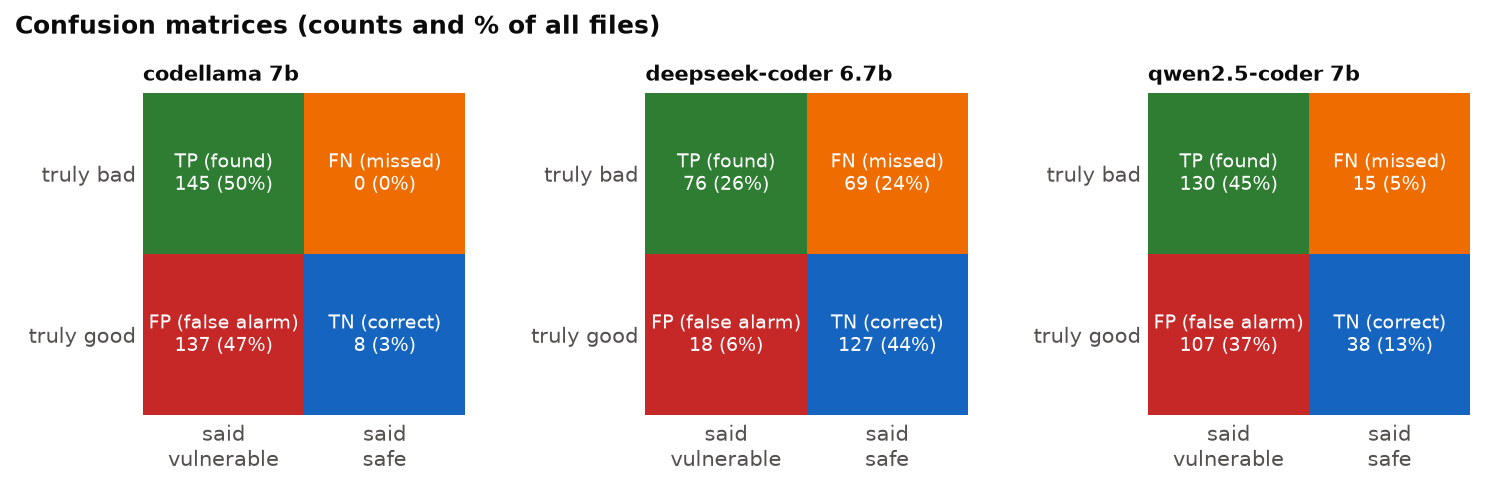

In [54]:

import matplotlib
matplotlib.rcParams['figure.dpi'] = 150
box_colours = [["#2E7D32", "#EF6C00"], ["#C62828", "#1565C0"]]
box_names = [["TP (found)", "FN (missed)"], ["FP (false alarm)", "TN (correct)"]]
fig, axes = plt.subplots(1, len(models), figsize=(3.4 * len(models), 3.2), squeeze=False)
for ax, (_, r) in zip(axes[0], overall.iterrows()):
    mat = [[r.TP, r.FN], [r.FP, r.TN]]
    ax.imshow([[matplotlib.colors.to_rgb(c) for c in row] for row in box_colours])
    for i in range(2):
        for j in range(2):
            v = mat[i][j]
            ax.text(j, i, f"{box_names[i][j]}\n{v} ({100 * v / r.Files:.0f}%)", ha="center", va="center", color="white", fontsize=9)
    ax.set_xticks([0, 1], ["said\nvulnerable", "said\nsafe"]); ax.set_yticks([0, 1], ["truly bad", "truly good"])
    ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
    ax.set_title(short[r.Model], loc="left", fontsize=10)
fig.suptitle("Confusion matrices (counts and % of all files)", x=.02, ha="left", fontweight="bold", color=INK)
fig.tight_layout(); fig.savefig(os.path.join(OUT, "fig1_confusion.png")); plt.show()

What is a confusion matrix: 
A confusion matrix shows, for each model, how many files it got right and how many it got wrong.
The rows show what the file really is (truly bad or truly good), and the columns show what the model said (vulnerable or safe). So every file ends up in one of the 4 boxes.

- Green box (TP): the file is bad and the model said vulnerable (correct)
- Blue box (TN): the file is safe and the model said safe (correct)
- Orange box (FN): the file is bad but the model said safe, so the bug was missed (mistake)
- Red box (FP): the file is safe but the model said vulnerable, a false alarm (mistake)

Result:

DeepSeek has the most green: it called 127 of the 145 safe files safe and gave only 18 false alarms, but it missed 69 bad files. CodeLlama and Qwen found most of the bad files (145 and 130), but they also gave many false alarms (137 and 107), so their warnings cannot be trusted much. Overall, DeepSeek is the most reliable of the three models.

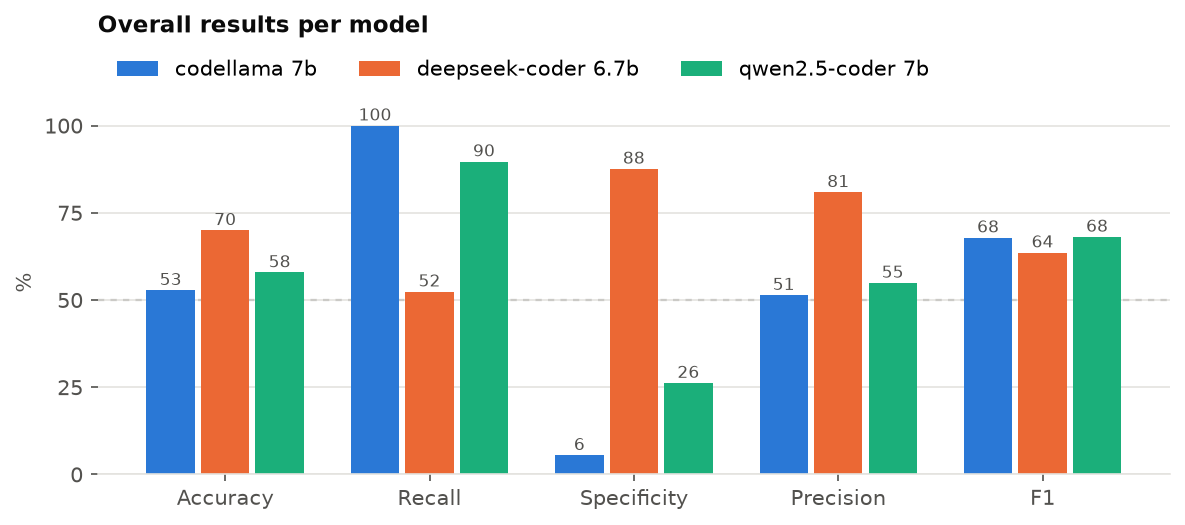

In [55]:
metrics = ["Accuracy %", "Recall %", "Specificity %", "Precision %", "F1 %"]
fig, ax = plt.subplots(figsize=(8, 3.6)); w = .8 / len(models)
for k, (_, r) in enumerate(overall.iterrows()):
    xs = [i + (k - (len(models) - 1) / 2) * w for i in range(len(metrics))]
    vals = [r[m] or 0 for m in metrics]
    ax.bar(xs, vals, width=w - .03, color=MODEL_COLORS[k % 4], label=short[r.Model], zorder=2)
    for x, v in zip(xs, vals):
        ax.text(x, v + 1.5, f"{v:.0f}", ha="center", fontsize=8, color=INK2)
ax.axhline(50, color=INK2, lw=1, ls=(0, (3, 3)), zorder=1)
ax.set_xticks(range(len(metrics)), [m.replace(" %", "") for m in metrics]); ax.set_ylim(0, 110)
ax.set_yticks(range(0, 101, 25)); ax.set_ylabel("%"); ax.grid(axis="y", color=GRID, zorder=0)
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.legend(frameon=False, loc="upper left", ncol=len(models), bbox_to_anchor=(0, 1.13))
ax.set_title("Overall results per model ", loc="left", pad=28)
fig.tight_layout(); fig.savefig(os.path.join(OUT, "fig2_overall.png")); plt.show()

This is overall result Graph. According to colours,
Blue = CodeLlama
Orange = DeepSeek
Green = Qwen

- Accuracy: Shows out of all 290 files, how many the model got right
- Recall: Shows out of the 145 bad files, how many the model found
- Specificity: Shows out of the 145 good files, how many the model correctly called safe
- Precision: Shows when the model said "vulnerable", how often it was really a bad file
- F1: Shows one score that combines precision and recall

Analysis: 

After analysis it is evidance that Codellama it provides 100% recall but upon verification and analysis of other parameter, we identified that specificity is 5.5%. which means model gives false alarm for 94.5% of files. MCC score for CodeLlama 0.168. It is almost like we can’t use it in real life develpoment. On other side results from qwen2.5-coder evidance that it provides 90% recall
with 73.8% of false alarm rate whci means it also struggles with false alarm. It provides 26.2% of specificity which indicates it flagged many safe files as vulnerable.


 ## 3. Results per CWE

In [56]:
per_cwe = pd.DataFrame([{"Model": m, "CWE": c, "Name": CWE_NAMES.get(c, ""),
                         **rates(det[(det.model == m) & (det.cwe == c)]),
                         **found_rates(det[(det.model == m) & (det.cwe == c)])}
                        for m in models for c in cwe_order])
save(per_cwe, "4_per_cwe.csv")
per_cwe[["Model", "CWE", "Files", "TP", "FN", "FP", "TN", "Accuracy %", "Recall %", "False alarm %",
         "MCC", "CWE related %", "Line ±2 %"]]

,Model,CWE,Files,TP,FN,FP,TN,Accuracy %,Recall %,False alarm %,MCC,CWE related %,Line ±2 %
0,codellama:7b,CWE78,50,25,0,25,0,50.0,100.0,100.0,0.000,0.0,56.0
1,codellama:7b,CWE121,50,25,0,24,1,52.0,100.0,96.0,0.143,96.0,88.0
2,codellama:7b,CWE122,50,25,0,23,2,54.0,100.0,92.0,0.204,96.0,100.0
3,codellama:7b,CWE190,50,25,0,22,3,56.0,100.0,88.0,0.253,12.0,88.0
4,codellama:7b,CWE416,50,25,0,23,2,54.0,100.0,92.0,0.204,64.0,100.0
5,codellama:7b,CWE476,40,20,0,20,0,50.0,100.0,100.0,0.000,45.0,90.0
6,deepseek-coder:6.7b,CWE78,50,10,15,8,17,54.0,40.0,32.0,0.083,0.0,90.0
7,deepseek-coder:6.7b,CWE121,50,11,14,5,20,62.0,44.0,20.0,0.257,100.0,100.0
8,deepseek-coder:6.7b,CWE122,50,12,13,5,20,64.0,48.0,20.0,0.296,66.7,100.0
9,deepseek-coder:6.7b,CWE190,50,5,20,0,25,60.0,20.0,0.0,0.333,20.0,100.0


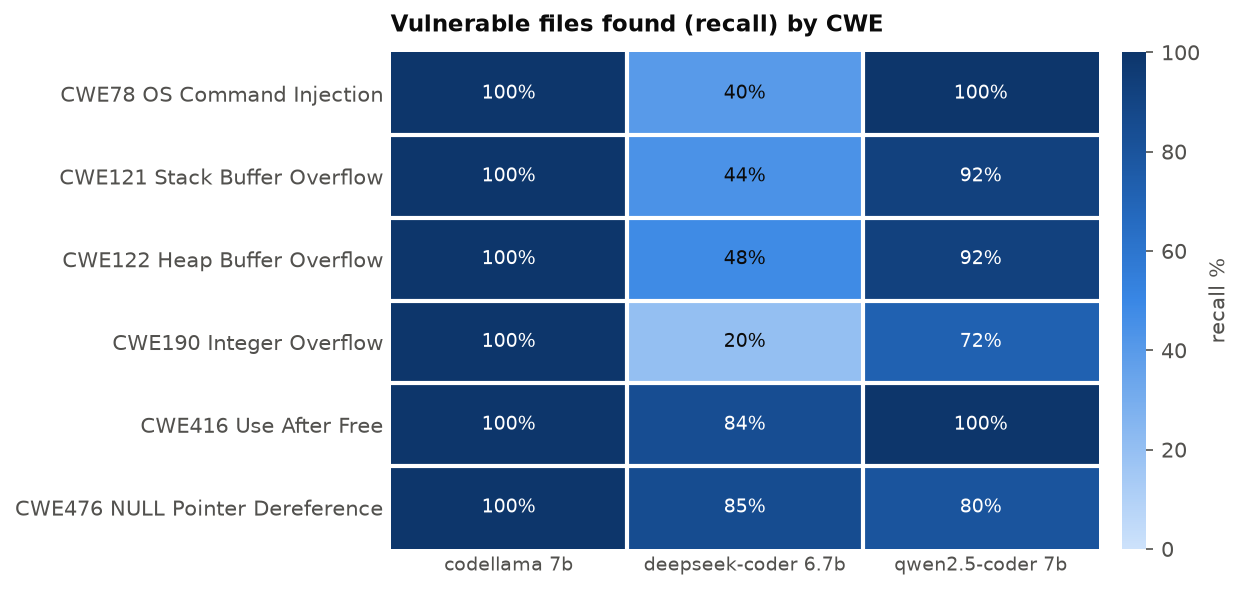

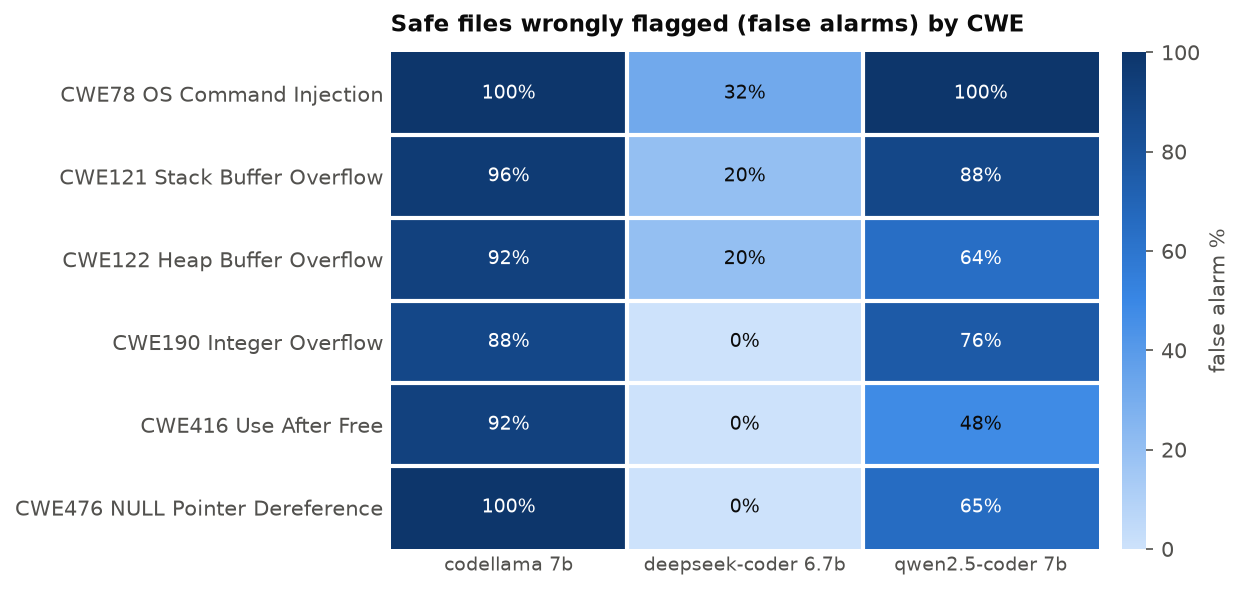

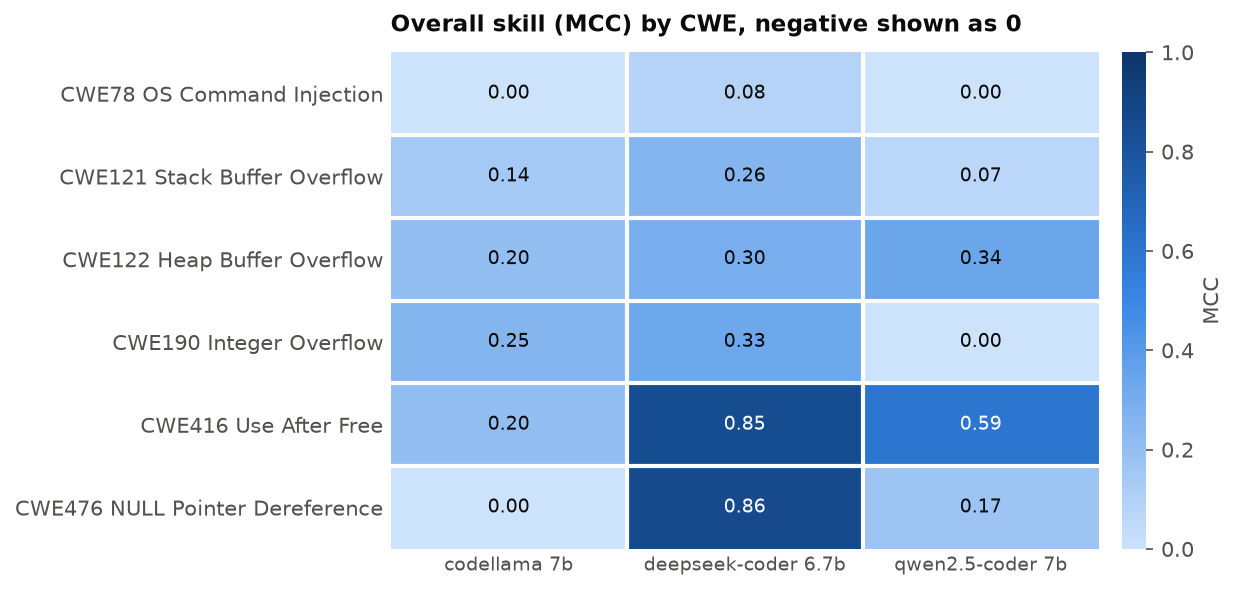

In [57]:
ylab = [f"{c} {CWE_NAMES.get(c, '')}" for c in cwe_order]
cols = [short[m] for m in models]
get = lambda col: [[per_cwe[(per_cwe.Model == m) & (per_cwe.CWE == c)][col].iloc[0] for m in models] for c in cwe_order]
heatmap(get("Recall %"), ylab, cols, "Vulnerable files found (recall) by CWE", "recall %", "fig3_recall_cwe.png")
heatmap(get("False alarm %"), ylab, cols, "Safe files wrongly flagged (false alarms) by CWE", "false alarm %", "fig4_falsealarm_cwe.png")
heatmap([[max(v, 0) for v in r] for r in get("MCC")], ylab, cols, "Overall skill (MCC) by CWE, negative shown as 0",
        "MCC", "fig5_mcc_cwe.png", vmax=1, cell="{:.2f}")

* Recall Graph: 
 For each type of vulnerability (CWE), the percentage of bad files that the model found.
 Darker blue = more bad files found.

CodeLlama found 100% of the bad files in every CWE, and Qwen also found most of them (72–100%). 
DeepSeek found much fewer bad files for CWE78, CWE121, CWE122 and especially CWE190 integer overflow (only 20%). 
But for CWE416 use after free and CWE476 NULL pointer, DeepSeek found most of them too (84% and 85%).

* False Alarm Graph:
 For each CWE, the percentage of safe files that the model wrongly called vulnerable. 
darker blue is bad, because it means more false alarms.

CodeLlama gave false alarms on 88 to 100% of the safe files in every CWE, so it said "vulnerable" for almost every file.
 This result explains that its 100% recall. Qwen also gave many false alarms, and for CWE78 it called every safe file vulnerable (100%). 
 DeepSeek gave the fewest false alarms compared to other LLM which is : 0% for CWE190, CWE416 and CWE 476, and at most 32% (CWE 78).

* MCC:
 MCC combines all four boxes (TP, FN, FP, TN) into one score. 1 means perfect, 0 means no better than guessing. Negative values are shown as 0.

This graph gives the clearest picture and overall overview. CodeLlama's MCC is close to 0 for all CWEs (0.00 to 0.25), so even with 100% recall it is not much better than guessing.
DeepSeek has the best MCC for most CWEs and is very good on CWE416 (0.85) and CWE476 (0.86): it found most bad files there without any false alarms.
CWE78 OS command injection founds  difficult to detect for all three models (MCC 0.08 or lower).
Qwen's best result was for the CWE416 (0.59).

Note: each CWE has only 25 bad and 25 good files (20 for CWE476), so one file changes the percentage by 4–5%. per cwe neeed to consider it. 

